# Migraciones internacionales: ¿importa la adyacencia entre países?
*Stock migratorio de la ONU (2024) como grafo dirigido y ponderado + test de hipótesis por permutaciones*

**Pregunta:** ¿el stock de migrantes entre dos países depende de que compartan frontera?

- **H₀ (nula):** la adyacencia no tiene relación con el stock migratorio. Las migraciones se distribuyen entre pares de países sin relación con el mapa de fronteras, es decir "al azar" respecto de la adyacencia.
- **H₁ (alternativa):** los pares de países limítrofes tienen más migración que lo esperable bajo H₀.

**Datos**
- UN DESA, *International Migrant Stock 2024* (stock por origen y destino, 1990-2024).
- Fronteras entre países (JSON del repo del TP, clave = código ISO3).
- Tabla auxiliar del repo del TP, solo para pasar de código numérico de la ONU a ISO3 y filtrar países válidos.

**Método (test de permutación tipo QAP):** se calcula un estadístico sobre los pares limítrofes y se compara con su distribución cuando se reasignan al azar los nombres de los países en el grafo de fronteras. Esto conserva la forma del grafo de fronteras (cantidad de pares limítrofes y de vecinos de cada nodo) y la matriz de migraciones, y rompe solo la relación entre ambos.

In [ ]:
# 1. Librerías y parámetros
import io, json, warnings
import requests
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ---- Parámetros ----
AÑO_PRINCIPAL = "2024"      # año del análisis principal
N_PERM        = 10_000      # cantidad de permutaciones (bajar a 2_000 si tarda)
SEMILLA       = 42
ALFA          = 0.05

URL_ONU = ("https://www.un.org/development/desa/pd/sites/www.un.org.development.desa.pd/"
           "files/undesa_pd_2024_ims_stock_by_sex_destination_and_origin.xlsx")
BASE_GH = "https://raw.githubusercontent.com/RexCaecos/ciencia_redes_uba/main/"
URL_AUX = BASE_GH + "aux_poblacion_coord.xlsx"
URL_FRONTERAS = BASE_GH + "paises_fronteras_completo.json"
HEADERS = {"User-Agent": "Mozilla/5.0"}   # la web de la ONU rechaza pedidos sin user-agent

## 2. Carga de datos

In [ ]:
def descargar(url, etiqueta):
    """Descarga una URL. Si falla, pide subir el archivo a mano (Colab)."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=120)
        r.raise_for_status()
        print(f"OK  {etiqueta}: {len(r.content)/1e6:.2f} MB")
        return r.content
    except Exception as e:
        print(f"ERROR descargando {etiqueta}: {e}")
        print(f"Descargalo a mano desde:\n  {url}\ny subilo acá.")
        from google.colab import files
        subido = files.upload()
        return next(iter(subido.values()))

bytes_onu        = descargar(URL_ONU, "ONU - stock migratorio 2024")
bytes_aux        = descargar(URL_AUX, "Tabla auxiliar de países (ISO3)")
bytes_fronteras  = descargar(URL_FRONTERAS, "Fronteras entre países")

fronteras = json.loads(bytes_fronteras)
print("Países en el JSON de fronteras:", len(fronteras))

OK  ONU - stock migratorio 2024: 6.01 MB
OK  Tabla auxiliar de países (ISO3): 1.62 MB
OK  Fronteras entre países: 0.03 MB
Países en el JSON de fronteras: 196


In [ ]:
# 2.1 Tabla ONU -> formato largo (origen, destino, año, migrantes)
raw = pd.read_excel(io.BytesIO(bytes_onu), sheet_name="Table 1", engine="openpyxl")

raw = raw.iloc[9:, :15].reset_index(drop=True)        # zona de datos (ambos sexos)
raw.columns = raw.iloc[0].astype(str)                 # primera fila = encabezados
raw = raw[1:].reset_index(drop=True)

cols = [c[:-2] if c.endswith(".0") else c for c in raw.columns]
# posiciones del archivo de la ONU: 1 = destino, 5 = origen, 7..14 = años
idx_codigos = [i for i, c in enumerate(cols) if "code" in c.lower()]
assert len(idx_codigos) == 2, f"No encontré las 2 columnas de código: {cols}"
cols[1], cols[5] = "destino", "origen"
cols[idx_codigos[0]], cols[idx_codigos[1]] = "cod_des", "cod_ori"   # primero destino, luego origen
raw.columns = cols

años = cols[7:15]
assert all(a.isdigit() for a in años), f"Columnas de años inesperadas: {años}"
print("Años disponibles:", años)

for a in años:
    raw[a] = pd.to_numeric(raw[a], errors="coerce").fillna(0)
raw["cod_des"] = pd.to_numeric(raw["cod_des"], errors="coerce")
raw["cod_ori"] = pd.to_numeric(raw["cod_ori"], errors="coerce")

onu = raw[["cod_ori", "cod_des", "origen", "destino"] + años].dropna(subset=["cod_ori", "cod_des"])
onu[["cod_ori", "cod_des"]] = onu[["cod_ori", "cod_des"]].astype(int)
print(f"Filas ONU (todas las entidades, incluye regiones): {len(onu):,}")
onu.head()

Años disponibles: ['1990', '1995', '2000', '2005', '2010', '2015', '2020', '2024']
Filas ONU (todas las entidades, incluye regiones): 28,030


,cod_ori,cod_des,origen,destino,1990,1995,2000,2005,2010,2015,2020,2024
0,900,900,World,World,153916063.0,163176002.0,174566152.0,192788721.0,221020392.0,250042020.0,275284032.0,304021813.0
1,1834,900,Sub-Saharan Africa,World,14124662.0,15183742.0,14584913.0,16004417.0,18243295.0,22763602.0,27134957.0,30661610.0
2,1833,900,Northern Africa and Western Asia,World,14986109.0,17216219.0,18728264.0,21198002.0,25429492.0,32508087.0,37196853.0,40529326.0
3,1831,900,Central and Southern Asia,World,30342957.0,27930630.0,30008559.0,32445580.0,39400759.0,46011893.0,48594959.0,53948417.0
4,1832,900,Eastern and South-Eastern Asia,World,14465509.0,17262816.0,20822011.0,24315849.0,30053666.0,34562856.0,38223520.0,41409235.0


In [ ]:
# 2.2 Países válidos + correspondencia código ONU -> ISO3
df_regiones = pd.read_excel(io.BytesIO(bytes_aux), sheet_name="Regiones", header=1)

status_validos = [
    "Member State", "CN Province", "CN Special Administrative Region",
    "Occupied Palestinan Territory", "NL Self-Governing Territory",
    "DK Self-Governing Territory", "The City of Vatican",
]  # mismo criterio que el notebook del TP
paises = df_regiones[(df_regiones["Type"] == "Country/Area") &
                     (df_regiones["status_un"].isin(status_validos))].copy()
paises["Location code"] = paises["Location code"].astype(int)

cod2iso = dict(zip(paises["Location code"], paises["ISO3 Alpha-code"]))
iso2nombre = dict(zip(paises["ISO3 Alpha-code"], paises["Region, subregion, country or area *"]))
print("Países/territorios válidos:", len(cod2iso))

Países/territorios válidos: 202


## 3. Construcción de las matrices
- **W[año]**: matriz de stock migratorio, `W[i, j]` = personas nacidas en `i` que residen en `j` (dirigida, diagonal en 0).
- **A**: matriz de adyacencia (simétrica) construida desde el JSON de fronteras.

In [ ]:
# 3.1 Matrices W por año (solo países válidos)
solo_paises = onu[onu["cod_ori"].isin(cod2iso) & onu["cod_des"].isin(cod2iso)].copy()
solo_paises["iso_ori"] = solo_paises["cod_ori"].map(cod2iso)
solo_paises["iso_des"] = solo_paises["cod_des"].map(cod2iso)

nodos = sorted(set(solo_paises["iso_ori"]) | set(solo_paises["iso_des"]))
pos = {iso: k for k, iso in enumerate(nodos)}
n = len(nodos)

W_por_año = {}
for a in años:
    M = np.zeros((n, n))
    i = solo_paises["iso_ori"].map(pos).to_numpy()
    j = solo_paises["iso_des"].map(pos).to_numpy()
    np.add.at(M, (i, j), solo_paises[a].to_numpy())
    np.fill_diagonal(M, 0)
    W_por_año[a] = M

print(f"Nodos (países): {n}")
print(f"Stock total {AÑO_PRINCIPAL}: {W_por_año[AÑO_PRINCIPAL].sum():,.0f} migrantes")

# 3.2 Matriz de adyacencia desde el JSON
A = np.zeros((n, n), dtype=bool)
sin_entrada = [iso for iso in nodos if iso not in fronteras]
vecinos_fuera = 0
for iso, info in fronteras.items():
    if iso not in pos:
        continue
    for v in info.get("vecinos", []):
        if v in pos:
            A[pos[iso], pos[v]] = True
        else:
            vecinos_fuera += 1
asimetricos = int((A != A.T).sum() // 2)
A = A | A.T                      # la adyacencia se trata como simétrica
np.fill_diagonal(A, False)

tipo = np.array([fronteras.get(iso, {}).get("tipo", "desconocido") for iso in nodos])
print(f"Pares limítrofes (no dirigidos): {A.sum()//2}")
print(f"Países sin entrada en el JSON de fronteras: {len(sin_entrada)} {sin_entrada[:15]}")
print(f"Pares con adyacencia declarada en un solo sentido (corregidos): {asimetricos}")
print(f"Vecinos del JSON que no están entre los nodos: {vecinos_fuera}")
print("Tipos de país:", pd.Series(tipo).value_counts().to_dict())

Nodos (países): 202
Stock total 2024: 278,458,411 migrantes
Pares limítrofes (no dirigidos): 311
Países sin entrada en el JSON de fronteras: 7 ['ABW', 'ATG', 'CUW', 'GRL', 'HKG', 'MAC', 'SXM']
Pares con adyacencia declarada en un solo sentido (corregidos): 1
Vecinos del JSON que no están entre los nodos: 10
Tipos de país: {'continental': 156, 'isla': 39, 'desconocido': 7}


## 4. El grafo dirigido y ponderado
Nodos = países, arista `i → j` con peso = migrantes nacidos en `i` residentes en `j`.

In [ ]:
W = W_por_año[AÑO_PRINCIPAL]

G = nx.DiGraph()
G.add_nodes_from((iso, {"nombre": iso2nombre.get(iso, iso), "tipo": t}) for iso, t in zip(nodos, tipo))
ii, jj = np.nonzero(W)
G.add_weighted_edges_from(
    (nodos[i], nodos[j], W[i, j]) for i, j in zip(ii, jj)
)
nx.set_edge_attributes(G, {(nodos[i], nodos[j]): bool(A[i, j]) for i, j in zip(ii, jj)}, "adyacente")

print(f"Grafo {AÑO_PRINCIPAL}: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas, "
      f"densidad {nx.density(G):.3f}")

en_ady = sum(d["weight"] for _, _, d in G.edges(data=True) if d["adyacente"])
tot = sum(d["weight"] for _, _, d in G.edges(data=True))
n_ady_aristas = sum(1 for _, _, d in G.edges(data=True) if d["adyacente"])
print(f"Aristas entre países limítrofes: {n_ady_aristas} de {int(A.sum())} pares dirigidos limítrofes posibles")
print(f"Parte del stock total que ocurre entre países limítrofes: {en_ady/tot:.1%}")
print(f"Parte de los pares dirigidos posibles que son limítrofes: {A.sum()/(n*(n-1)):.2%}")

top = sorted(G.out_degree(weight="weight"), key=lambda x: -x[1])[:5]
print("\nMayores emisores (stock):", [(iso2nombre.get(k, k), int(v)) for k, v in top])
top = sorted(G.in_degree(weight="weight"), key=lambda x: -x[1])[:5]
print("Mayores receptores (stock):", [(iso2nombre.get(k, k), int(v)) for k, v in top])

Grafo 2024: 202 nodos, 8417 aristas, densidad 0.207
Aristas entre países limítrofes: 560 de 622 pares dirigidos limítrofes posibles
Parte del stock total que ocurre entre países limítrofes: 35.6%
Parte de los pares dirigidos posibles que son limítrofes: 1.53%

Mayores emisores (stock): [('India', 18532179), ('China', 11692124), ('Mexico', 11594827), ('Ukraine', 9769216), ('Russian Federation', 9134056)]
Mayores receptores (stock): [('United States of America', 46930825), ('Germany', 13612825), ('Saudi Arabia', 13394579), ('Canada', 8805641), ('United Kingdom', 8730397)]


## 5. Test de hipótesis (permutaciones)

Estadísticos, todos calculados sobre los pares limítrofes y donde **valores altos van en contra de H₀**:

| | Estadístico | Qué mide |
|---|---|---|
| **T1** | parte del stock total que fluye entre países limítrofes | peso de la adyacencia en el volumen migratorio |
| **T2** | proporción de pares limítrofes que tienen alguna migración registrada | adyacencia y *existencia* de arista |
| **T3** | promedio de log₁₀(1 + migrantes) en los pares limítrofes | adyacencia e *intensidad* típica del flujo |

**Distribución nula:** se permutan al azar los países en la matriz de adyacencia (`A' = A[p][:, p]`) y se recalculan T1-T3. P-valor unilateral: `(1 + #{T_perm ≥ T_obs}) / (1 + N_PERM)`.

In [ ]:
def matrices_estadisticos(W):
    """Devuelve las 3 matrices M tales que T_k = sum(M_k * A) / constante."""
    off = ~np.eye(len(W), dtype=bool)
    M1 = W / W.sum()
    M2 = ((W > 0) & off).astype(float)
    M3 = np.where(off, np.log10(1 + W), 0.0)
    return np.stack([M1, M2, M3])

def qap_test(Ws, A, n_perm=N_PERM, semilla=SEMILLA):
    """
    Ws: dict {etiqueta: matriz W}. A: adyacencia booleana.
    Devuelve (observado, nulos) con forma (K,) y (n_perm, K), K = 3 * len(Ws).
    """
    rng = np.random.default_rng(semilla)
    n_ady = A.sum()
    stack = np.concatenate([matrices_estadisticos(W) for W in Ws.values()]).astype(np.float32)
    K, n, _ = stack.shape
    flat = stack.reshape(K, n * n)
    escala = np.tile([1.0, 1.0 / n_ady, 1.0 / n_ady], len(Ws)).astype(np.float32)
    # T1 ya está normalizado en M1 (suma 1)

    obs = (flat @ A.astype(np.float32).ravel()) * escala
    nulos = np.empty((n_perm, K), dtype=np.float32)
    for b in range(n_perm):
        p = rng.permutation(n)
        Ap = A[np.ix_(p, p)].astype(np.float32).ravel()
        nulos[b] = (flat @ Ap) * escala
    return obs, nulos

def resumen(obs, nulos, etiquetas):
    pv = (1 + (nulos >= obs).sum(axis=0)) / (1 + len(nulos))
    z = (obs - nulos.mean(axis=0)) / nulos.std(axis=0)
    return pd.DataFrame({
        "etiqueta": etiquetas,
        "observado": obs,
        "media_nula": nulos.mean(axis=0),
        "ratio_obs/nula": obs / nulos.mean(axis=0),
        "z": z,
        "p_valor": pv,
        "rechaza_H0": pv < ALFA,
    })

NOMBRES_T = ["T1 parte del stock", "T2 prop. con arista", "T3 media log10(1+x)"]
obs, nulos = qap_test({AÑO_PRINCIPAL: W_por_año[AÑO_PRINCIPAL]}, A)
res_principal = resumen(obs, nulos, NOMBRES_T)
res_principal.round(4)

,etiqueta,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 parte del stock,0.3559,0.0154,23.105,35.431702,0.0001,True
1,T2 prop. con arista,0.9003,0.2076,4.336,31.804001,0.0001,True
2,T3 media log10(1+x),3.9430,0.5921,6.660,46.096401,0.0001,True


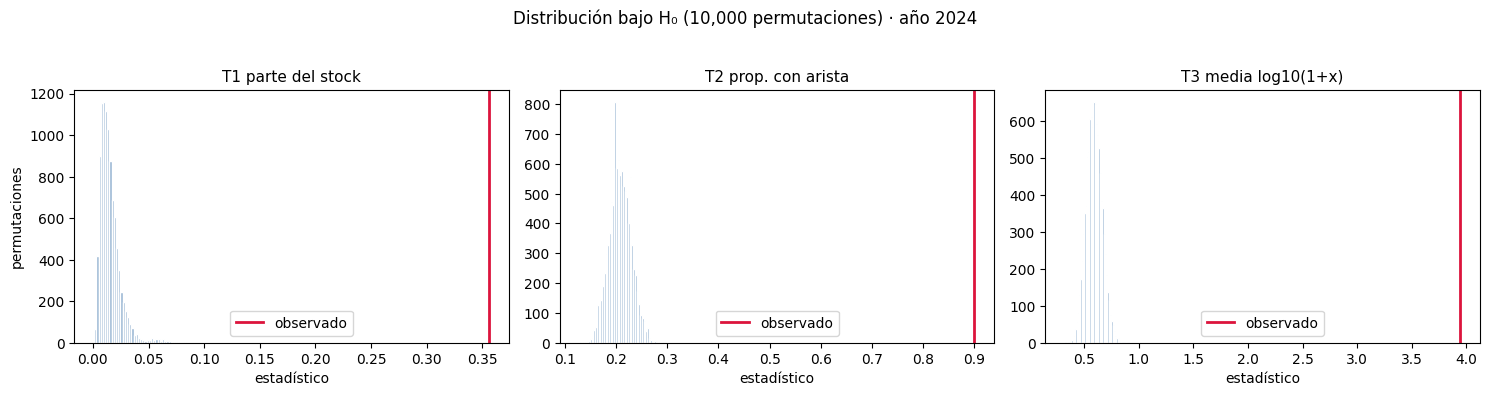

In [ ]:
# Distribuciones nulas vs. valor observado
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for k, ax in enumerate(axs):
    ax.hist(nulos[:, k], bins=50, color="#9bb7d4", edgecolor="white")
    ax.axvline(obs[k], color="crimson", lw=2, label="observado")
    ax.set_title(NOMBRES_T[k], fontsize=11)
    ax.set_xlabel("estadístico")
    ax.legend()
axs[0].set_ylabel("permutaciones")
fig.suptitle(f"Distribución bajo H₀ ({N_PERM:,} permutaciones) · año {AÑO_PRINCIPAL}", y=1.03)
plt.tight_layout(); plt.show()

## 6. Chequeos de robustez

1. **Test complementario (Mann-Whitney):** compara los flujos de pares limítrofes contra los no limítrofes. Sirve como segunda opinión, pero asume independencia entre pares, algo que no se cumple en una red. El test de permutación de arriba es el principal.
2. **Solo países continentales:** las islas no pueden tener frontera terrestre, así que quedan siempre en el grupo "no limítrofe" y pueden sesgar el resultado. Se repite el test sin ellas.
3. **Todos los años (1990-2024):** para ver si el resultado se mantiene.

In [ ]:
# 6.1 Mann-Whitney (pares dirigidos i != j)
off = ~np.eye(n, dtype=bool)
x_ady = np.log10(1 + W[A & off])
x_no  = np.log10(1 + W[~A & off])
u, p_mw = stats.mannwhitneyu(x_ady, x_no, alternative="greater")
print(f"Mann-Whitney ({AÑO_PRINCIPAL}): mediana log10(1+x) limítrofes = {np.median(x_ady):.2f} vs "
      f"no limítrofes = {np.median(x_no):.2f} | p = {p_mw:.2e}")
print(f"Mediana de migrantes: limítrofes = {np.median(W[A & off]):,.0f} · no limítrofes = {np.median(W[~A & off]):,.0f}")

# 6.2 Solo países continentales
cont = np.where(tipo == "continental")[0]
if len(cont) > 10:
    A_c = A[np.ix_(cont, cont)]
    W_c = W[np.ix_(cont, cont)]
    obs_c, nulos_c = qap_test({AÑO_PRINCIPAL: W_c}, A_c)
    print(f"\nSolo continentales: {len(cont)} países, {A_c.sum()//2} pares limítrofes")
    display(resumen(obs_c, nulos_c, NOMBRES_T).round(4))
else:
    print("\nNo se pudo identificar el tipo 'continental' en el JSON; se omite este chequeo.")

Mann-Whitney (2024): mediana log10(1+x) limítrofes = 4.25 vs no limítrofes = 0.00 | p = 0.00e+00
Mediana de migrantes: limítrofes = 17,852 · no limítrofes = 0

Solo continentales: 156 países, 311 pares limítrofes


,etiqueta,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 parte del stock,0.4100,0.0259,15.8047,28.509701,0.0001,True
1,T2 prop. con arista,0.9003,0.2551,3.5290,31.701300,0.0001,True
2,T3 media log10(1+x),3.9430,0.7601,5.1874,44.112202,0.0001,True


In [ ]:
# 6.3 Todos los años
obs_a, nulos_a = qap_test(W_por_año, A, n_perm=min(N_PERM, 5_000))
etiquetas = [f"{a} · {t[:2]}" for a in W_por_año for t in NOMBRES_T]
res_all = resumen(obs_a, nulos_a, etiquetas)
tabla = (res_all.assign(año=lambda d: d["etiqueta"].str[:4], est=lambda d: d["etiqueta"].str[-2:])
         .pivot(index="año", columns="est", values="ratio_obs/nula"))
print("Ratio observado / esperado bajo H₀ (1 = sin efecto de la adyacencia):")
display(tabla.round(2))
print("P-valores:")
display(res_all.assign(año=lambda d: d["etiqueta"].str[:4], est=lambda d: d["etiqueta"].str[-2:])
        .pivot(index="año", columns="est", values="p_valor").round(4))

Ratio observado / esperado bajo H₀ (1 = sin efecto de la adyacencia):


est,T1,T2,T3
año,,,
1990,32.020000,4.78,7.81
1995,30.129999,4.65,7.55
2000,28.700001,4.59,7.34
2005,26.660000,4.55,7.14
2010,25.070000,4.44,6.97
2015,23.870001,4.33,6.85
2020,23.219999,4.33,6.69
2024,22.980000,4.34,6.65


P-valores:


est,T1,T2,T3
año,,,
1990,0.0002,0.0002,0.0002
1995,0.0002,0.0002,0.0002
2000,0.0002,0.0002,0.0002
2005,0.0002,0.0002,0.0002
2010,0.0002,0.0002,0.0002
2015,0.0002,0.0002,0.0002
2020,0.0002,0.0002,0.0002
2024,0.0002,0.0002,0.0002


## 7. Cómo leer los resultados

- Si **p < 0.05** en T1-T3, se rechaza H₀: los pares limítrofes concentran más migración de la esperable si la adyacencia no importara. `ratio_obs/nula` dice cuántas veces más.
- Si **no se rechaza**, no se encontró evidencia de que la adyacencia se relacione con el stock migratorio. No prueba que no exista relación.

**Límites a mencionar en el informe**
- **Correlación, no causalidad:** adyacencia suele ir con distancia corta, idioma, historia compartida, bloques económicos (UE, Mercosur, CEDEAO) y migración de refugiados. Para separar el efecto de la frontera habría que controlar por distancia, población y PBI (modelo de gravedad).
- **Stock, no flujo:** el dato es acumulado (nacidos en `i` que viven en `j`), no migraciones anuales.
- **Los países grandes pesan mucho** en T1. Por eso conviene mirar también T2 y T3.
- **Las islas** nunca son limítrofes (ver el chequeo de países continentales).
- **Variantes posibles:** un modelo de gravedad con adyacencia como regresor (por ejemplo PPML), o tratar la adyacencia por vecindad de 2.º orden.